# CS5004 Advanced Topics in Generative AI — Assignment 2
## Diffusion Models, Vision Transformers and Swin

**Name:** Sharoz Haseeb  |  **Roll number:** 26L-9005 → last digit **d = 5**

| Part | What my digit gives me |
|---|---|
| A (DDPM) | classes d = **5 Sandal**, (d+3) mod 10 = **8 Bag**, (d+6) mod 10 = **1 Trouser** |
| C (by hand) | image **448 × 448 × 3**, **C = 128** |

**How to run:** Runtime → Change runtime type → **T4 GPU**, then run the cells from top to bottom.
Every part saves its figures to `outputs/figures/` and its numbers to `outputs/results.json`,
so the report can be built from them without copying numbers by hand.

Contents
- **0.** Setup
- **Part A** — DDPM from scratch: A1 schedules, A2 training, A3 sampling
- **Part B** — Inside ViT and Swin: B1 shapes, B2 linear probe
- **Part C** — Swin dimensions and attention cost by hand

## 0. Setup

In [1]:
# Install the two libraries we need (Colab already has torch, torchvision, sklearn, matplotlib).
# pillow-heif lets PIL open iPhone .HEIC photos.
!pip install -q diffusers timm pillow-heif
# Colab ships an older torchao that breaks the newest diffusers import. We don't use it, so remove it.
!pip uninstall -y -q torchao

In [2]:
import json
import math
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn.functional as F
import torchvision

# Let PIL open .HEIC photos if pillow-heif is installed (harmless if it is not).
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except ImportError:
    pass

import diffusers, timm, sklearn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
print("torch", torch.__version__, "| diffusers", diffusers.__version__,
      "| timm", timm.__version__, "| sklearn", sklearn.__version__)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

device: cuda
torch 2.11.0+cu130 | diffusers 0.41.0 | timm 1.0.30 | sklearn 1.6.1
GPU: Tesla T4


In [3]:
# ---------------- My settings ----------------
ROLL = "26L-9005"
d = int(ROLL[-1])                       # last digit of the roll number -> 5
SEED = 9005                             # fixed seed (from my roll number) so every run is repeatable

# QUICK_TEST = True runs everything with tiny settings (a few minutes) just to check the code.
# Keep it False for the real run.
QUICK_TEST = False

# Save outputs to Google Drive so checkpoints survive a Colab disconnect.
USE_DRIVE = True
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/CS5004_A2")
else:
    BASE = Path("A2_work")

# Quick tests go to a separate folder, so their tiny checkpoints can never be reused by the real run.
OUT = BASE / ("outputs_quicktest" if QUICK_TEST else "outputs")   # everything we produce
FIG_DIR = OUT / "figures"
CKPT_DIR = OUT / "ckpt"
PHOTO_DIR = BASE / "photos"             # Part B: photos/<class_name>/*.jpg
DATA_DIR = Path("data")                 # Fashion-MNIST download (local, fast)
for folder in (FIG_DIR, CKPT_DIR, PHOTO_DIR, DATA_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("d =", d, "| SEED =", SEED, "| outputs in", OUT.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
d = 5 | SEED = 9005 | outputs in /content/drive/MyDrive/CS5004_A2/outputs


In [4]:
# ---------------- Small helpers used everywhere ----------------
RESULTS_FILE = OUT / "results.json"
RESULTS = json.loads(RESULTS_FILE.read_text()) if RESULTS_FILE.exists() else {}


def save_results():
    """Write all numbers collected so far to results.json."""
    RESULTS_FILE.write_text(json.dumps(RESULTS, indent=2))


def save_fig(name):
    """Save the current matplotlib figure into outputs/figures and show it."""
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path.name)
    plt.show()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def to_display(x):
    """Image tensor in [-1, 1] -> numpy array in [0, 1] for plt.imshow."""
    return ((x.clamp(-1, 1) + 1) / 2).squeeze().detach().cpu().numpy()

---
# Part A: A Small Diffusion Model from Scratch

**Rules I follow:** only `diffusers.UNet2DModel` is used (as the network, with random weights).
The noise schedules, forward process, training loop and sampling loop are all written below in plain PyTorch.

### A.0 Load my three Fashion-MNIST classes
Each image is 28 × 28. I pad 2 pixels on every side to get 32 × 32 and scale pixels from [0, 255] to [−1, 1].

In [5]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
MY_CLASSES = [d, (d + 3) % 10, (d + 6) % 10]
print("My classes:", [(c, CLASS_NAMES[c]) for c in MY_CLASSES])

fmnist = torchvision.datasets.FashionMNIST(DATA_DIR, train=True, download=True)

# fmnist.data is a uint8 tensor (60000, 28, 28); fmnist.targets holds the labels.
keep = torch.isin(fmnist.targets, torch.tensor(MY_CLASSES))
x = fmnist.data[keep].float() / 255.0          # (N, 28, 28) in [0, 1]
x = F.pad(x, (2, 2, 2, 2))                      # (N, 32, 32), padded with zeros (= black)
x = x * 2 - 1                                   # [0, 1] -> [-1, 1]
X_TRAIN = x.unsqueeze(1)                        # (N, 1, 32, 32): add the channel dimension
Y_TRAIN = fmnist.targets[keep]

if QUICK_TEST:
    X_TRAIN, Y_TRAIN = X_TRAIN[:512], Y_TRAIN[:512]

print("training images:", X_TRAIN.shape[0], "| shape:", tuple(X_TRAIN.shape),
      "| range:", X_TRAIN.min().item(), "to", X_TRAIN.max().item())
print("per class:", {CLASS_NAMES[c]: int((Y_TRAIN == c).sum()) for c in MY_CLASSES})

My classes: [(5, 'Sandal'), (8, 'Bag'), (1, 'Trouser')]
training images: 18000 | shape: (18000, 1, 32, 32) | range: -1.0 to 1.0
per class: {'Sandal': 6000, 'Bag': 6000, 'Trouser': 6000}


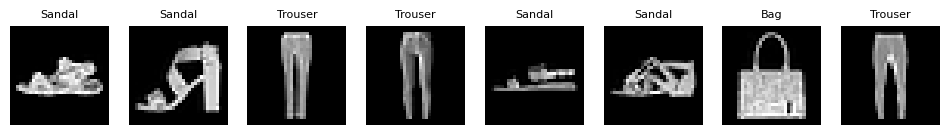

In [6]:
# Look at a few training images to make sure the data is right.
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax, i in zip(axes, torch.randperm(len(X_TRAIN))[:8]):
    ax.imshow(to_display(X_TRAIN[i]), cmap="gray")
    ax.set_title(CLASS_NAMES[Y_TRAIN[i]], fontsize=8)
    ax.axis("off")
plt.show()

## A1. Forward process and noise schedules

Notation (0-indexed, t = 0 … T−1 with T = 1000):
- β<sub>t</sub> = variance of the noise added at step t, α<sub>t</sub> = 1 − β<sub>t</sub>, ᾱ<sub>t</sub> = α<sub>0</sub> α<sub>1</sub> ⋯ α<sub>t</sub>.
- **Linear schedule:** β goes linearly from 10⁻⁴ to 0.02.
- **Cosine schedule** (Nichol & Dhariwal, 2021): ᾱ(t) = f(t)/f(0) with f(t) = cos²( ((t/T) + s)/(1 + s) · π/2 ), s = 0.008.
  We turn it into betas with β<sub>t</sub> = 1 − ᾱ(t+1)/ᾱ(t) and clip β at 0.999 so the last step does not have β = 1.

**Closed-form forward process:** x<sub>t</sub> = √ᾱ<sub>t</sub> · x<sub>0</sub> + √(1 − ᾱ<sub>t</sub>) · ε, with ε ~ N(0, I).
This lets us jump straight from a clean image to any noise level t in one step.

In [7]:
T = 1000


def linear_betas(T, beta_start=1e-4, beta_end=0.02):
    return torch.linspace(beta_start, beta_end, T)


def cosine_betas(T, s=0.008):
    # alpha_bar(t) for t = 0..T (T+1 values), normalised so alpha_bar(0) = 1
    steps = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos(((steps / T) + s) / (1 + s) * math.pi / 2) ** 2
    alpha_bar = f / f[0]
    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]          # T values
    return betas.clamp(max=0.999).float()


class Schedule:
    """Holds beta_t, alpha_t and alpha_bar_t for one noise schedule."""

    def __init__(self, name, betas):
        self.name = name
        self.betas = betas.to(DEVICE)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)


SCHEDULES = {
    "linear": Schedule("linear", linear_betas(T)),
    "cosine": Schedule("cosine", cosine_betas(T)),
}


def q_sample(x0, t, eps, sched):
    """Forward process in closed form: x_t = sqrt(abar_t) * x0 + sqrt(1 - abar_t) * eps.
    x0, eps: (B, 1, 32, 32); t: (B,) integer timesteps."""
    abar = sched.alpha_bars[t].view(-1, 1, 1, 1)        # reshape so it broadcasts over pixels
    return abar.sqrt() * x0 + (1 - abar).sqrt() * eps


for name, s in SCHEDULES.items():
    print(f"{name:6s}: beta[0]={s.betas[0].item():.2e}  beta[-1]={s.betas[-1].item():.4f}  "
          f"abar[0]={s.alpha_bars[0].item():.4f}  abar[999]={s.alpha_bars[-1].item():.2e}")

linear: beta[0]=1.00e-04  beta[-1]=0.0200  abar[0]=0.9999  abar[999]=4.04e-05
cosine: beta[0]=4.13e-05  beta[-1]=0.9990  abar[0]=1.0000  abar[999]=2.43e-09


saved A1_alpha_bar.png


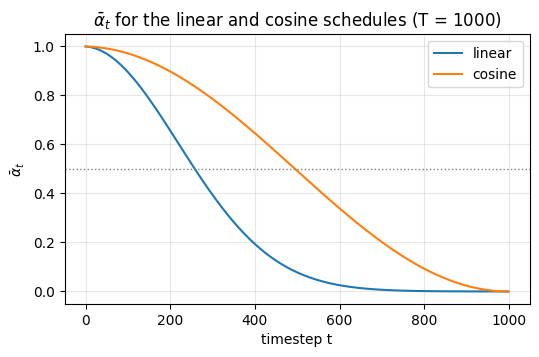

,0,100,250,500,750,999
linear,0.99990,0.89514,0.52142,0.07780,0.00330,0.00004
cosine,0.99996,0.97158,0.84589,0.49229,0.14318,0.00000


In [8]:
# Plot alpha_bar_t against t for both schedules on one figure.
plt.figure(figsize=(6, 3.5))
for name, s in SCHEDULES.items():
    plt.plot(s.alpha_bars.cpu(), label=name)
plt.axhline(0.5, color="gray", ls=":", lw=1)
plt.xlabel("timestep t")
plt.ylabel(r"$\bar{\alpha}_t$")
plt.title(r"$\bar{\alpha}_t$ for the linear and cosine schedules (T = 1000)")
plt.legend()
plt.grid(alpha=0.3)
save_fig("A1_alpha_bar")

# Numbers that back up the written explanation below.
A1_T_SHOW = [0, 100, 250, 500, 750, 999]
RESULTS["A1"] = {}
for name, s in SCHEDULES.items():
    abar = s.alpha_bars.cpu()
    RESULTS["A1"][name] = {
        "alpha_bar_at": {t: round(abar[t].item(), 5) for t in A1_T_SHOW},
        "first_t_below_0.5": int((abar < 0.5).nonzero()[0]),
        "first_t_below_0.01": int((abar < 0.01).nonzero()[0]),
    }
save_results()
pd.DataFrame({name: RESULTS["A1"][name]["alpha_bar_at"] for name in SCHEDULES}).T

saved A1_forward_grid.png


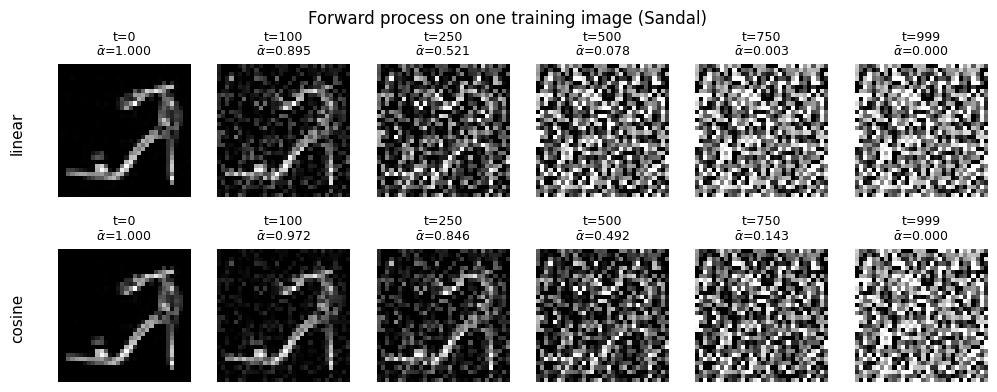

In [9]:
# One training image at t = 0, 100, 250, 500, 750, 999 under each schedule (2 x 6 grid).
# The same noise eps is used for both rows so the only difference is the schedule.
set_seed(SEED)
x0 = X_TRAIN[0:1].to(DEVICE)
eps = torch.randn_like(x0)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for row, (name, s) in enumerate(SCHEDULES.items()):
    for col, t in enumerate(A1_T_SHOW):
        xt = q_sample(x0, torch.tensor([t], device=DEVICE), eps, s)
        axes[row, col].imshow(to_display(xt), cmap="gray")
        axes[row, col].set_title(f"t={t}\n" + r"$\bar\alpha$=" + f"{s.alpha_bars[t].item():.3f}", fontsize=9)
        axes[row, col].axis("off")
    axes[row, 0].text(-12, 16, name, rotation=90, va="center", fontsize=11)
plt.suptitle(f"Forward process on one training image ({CLASS_NAMES[Y_TRAIN[0]]})")
save_fig("A1_forward_grid")

**Which schedule destroys the image faster, and why it matters (A1 answer).**

The **linear** schedule destroys the image faster: its ᾱ<sub>t</sub> drops below 0.5 at t = 259 and below 0.01 at t = 673,
while the cosine ᾱ<sub>t</sub> reaches 0.5 only at t = 496 and 0.01 at t = 935 (see the table above).
In the grid the object is barely visible at t = 500 under the linear schedule (ᾱ ≈ 0.08) but still clear under the cosine
schedule (ᾱ ≈ 0.49).
Because training picks t uniformly from 0…999, about a third of the linear schedule's timesteps give the network inputs that are
practically pure noise, where there is very little to learn.
The cosine schedule destroys the image more evenly over the timesteps, so more of the same training budget is spent on partly
noisy images where the network learns useful denoising, which matters most for small 32 × 32 images like ours.

## A2. Training with the ε-prediction loss

**Network:** a small `UNet2DModel` built from a configuration (random weights, no `from_pretrained`).

**DDPM training step** (written by me):
1. take a batch of clean images x<sub>0</sub>,
2. sample t uniformly from {0, …, 999} and noise ε ~ N(0, I),
3. build x<sub>t</sub> with the closed form from A1,
4. predict ε<sub>θ</sub>(x<sub>t</sub>, t) with the U-Net,
5. minimise the mean squared error ‖ε − ε<sub>θ</sub>‖².

Both models (linear and cosine) use **identical settings**: same U-Net, seed, batch size, learning rate and number of epochs.
The number of epochs is picked once, by timing a few training steps, so that each model trains for about 15 minutes.
Each epoch is 18,000 // 128 = 140 full batches (the last 80 images of the shuffled order are skipped that epoch).

In [10]:
from diffusers import UNet2DModel


def make_unet():
    """Small U-Net for 32x32 grayscale images, built from a config -> random weights.
    Resolutions 32 -> 16 -> 8; self-attention only at the lowest resolution (8x8), which keeps training fast."""
    return UNet2DModel(
        sample_size=32,
        in_channels=1,
        out_channels=1,
        layers_per_block=2,
        block_out_channels=(32, 64, 128),
        down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D"),
        up_block_types=("AttnUpBlock2D", "UpBlock2D", "UpBlock2D"),
    ).to(DEVICE)


n_params = sum(p.numel() for p in make_unet().parameters())
print(f"U-Net parameters: {n_params:,}")

U-Net parameters: 3,939,393


In [11]:
# ---------------- Training settings (same for both models) ----------------
BATCH_SIZE = 128
LR = 5e-4                       # a bit higher than the usual 2e-4 because we only train ~15 minutes
TARGET_MINUTES = 15 if not QUICK_TEST else 0.3
REUSE_CHECKPOINTS = True        # if a checkpoint already exists, load it instead of training again


def train_step(model, opt, x0, sched):
    """One DDPM training step with the epsilon-prediction loss. Returns the loss value."""
    t = torch.randint(0, T, (x0.shape[0],), device=DEVICE)   # 1) random timestep per image
    eps = torch.randn_like(x0)                                 # 2) random noise
    xt = q_sample(x0, t, eps, sched)                           # 3) noisy image (closed form)
    eps_pred = model(xt, t).sample                             # 4) predicted noise
    loss = F.mse_loss(eps_pred, eps)                           # 5) || eps - eps_theta ||^2
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
    return loss.item()


def new_training_objects():
    model = make_unet()
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    return model, opt


def choose_epochs(target_minutes, n_timing_steps=30):
    """Time a few training steps on a throwaway model and pick the number of epochs
    that fills about target_minutes. Both real models then use this same number."""
    model, opt = new_training_objects()
    x0 = X_TRAIN[:BATCH_SIZE].to(DEVICE)
    for _ in range(5):                                          # warm-up (CUDA start-up cost)
        train_step(model, opt, x0, SCHEDULES["linear"])
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    for _ in range(n_timing_steps):
        train_step(model, opt, x0, SCHEDULES["linear"])
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    sec_per_step = (time.time() - start) / n_timing_steps
    steps_per_epoch = len(X_TRAIN) // BATCH_SIZE
    epochs = max(1, round(target_minutes * 60 / (sec_per_step * steps_per_epoch)))
    print(f"{sec_per_step * 1000:.1f} ms/step, {steps_per_epoch} steps/epoch -> {epochs} epochs")
    return epochs


def epochs_from_checkpoints():
    """If a model was already trained (e.g. before a Colab disconnect), reuse its number of epochs,
    so both models are guaranteed to get identical settings."""
    for path in sorted(CKPT_DIR.glob("ddpm_*.pt")):
        return torch.load(path, map_location="cpu")["info"]["epochs"]
    return None


EPOCHS = (REUSE_CHECKPOINTS and epochs_from_checkpoints()) or choose_epochs(TARGET_MINUTES)
print("EPOCHS =", EPOCHS)

232.8 ms/step, 140 steps/epoch -> 28 epochs
EPOCHS = 28


In [12]:
def train_model(sched):
    """Train one DDPM from scratch with the given schedule and save a checkpoint."""
    ckpt_path = CKPT_DIR / f"ddpm_{sched.name}.pt"
    if REUSE_CHECKPOINTS and ckpt_path.exists():
        ckpt = torch.load(ckpt_path, map_location=DEVICE)
        model = make_unet()
        model.load_state_dict(ckpt["model"])
        info = ckpt["info"]
        print(f"loaded existing checkpoint {ckpt_path.name} (delete it to retrain)")
        print({k: v for k, v in info.items() if k != "losses"})     # the settings it was trained with
        assert info.get("classes") == MY_CLASSES, "checkpoint was trained on other classes - delete outputs/ckpt"
        assert info["epochs"] == EPOCHS and info["train_images"] == len(X_TRAIN), "checkpoint has different settings"
        return model, info

    set_seed(SEED)                                   # same seed -> same init and data order
    model, opt = new_training_objects()
    data = X_TRAIN.to(DEVICE)                        # 18,000 x 1 x 32 x 32 fits easily on the GPU
    losses = []
    model.train()
    start = time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(data), device=DEVICE)          # shuffle every epoch
        for i in range(0, len(data) - BATCH_SIZE + 1, BATCH_SIZE):  # drop the last partial batch
            x0 = data[perm[i:i + BATCH_SIZE]]
            losses.append(train_step(model, opt, x0, sched))
        assert np.isfinite(losses[-1]), "loss became NaN/inf - training diverged"
        print(f"[{sched.name}] epoch {epoch + 1}/{EPOCHS}  "
              f"mean loss {np.mean(losses[-(len(data) // BATCH_SIZE):]):.4f}  "
              f"elapsed {(time.time() - start) / 60:.1f} min")
    train_time = time.time() - start

    info = {
        "schedule": sched.name, "classes": MY_CLASSES, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR,
        "optimizer": "AdamW", "steps": len(losses),
        "train_images": len(data), "train_time_s": round(train_time, 1),
        "final_loss_last_epoch": round(float(np.mean(losses[-(len(data) // BATCH_SIZE):])), 4),
        "unet_params": n_params, "losses": losses,
    }
    torch.save({"model": model.state_dict(), "info": info}, ckpt_path)
    print(f"saved {ckpt_path}  ({train_time / 60:.1f} min)")
    return model, info


MODELS, TRAIN_INFO = {}, {}

In [13]:
# Train the LINEAR-schedule model (about 15 minutes on a T4).
MODELS["linear"], TRAIN_INFO["linear"] = train_model(SCHEDULES["linear"])

[linear] epoch 1/28  mean loss 0.0986  elapsed 0.5 min
[linear] epoch 2/28  mean loss 0.0482  elapsed 1.1 min
[linear] epoch 3/28  mean loss 0.0405  elapsed 1.7 min
[linear] epoch 4/28  mean loss 0.0383  elapsed 2.2 min
[linear] epoch 5/28  mean loss 0.0370  elapsed 2.8 min
[linear] epoch 6/28  mean loss 0.0352  elapsed 3.4 min
[linear] epoch 7/28  mean loss 0.0345  elapsed 4.0 min
[linear] epoch 8/28  mean loss 0.0337  elapsed 4.6 min
[linear] epoch 9/28  mean loss 0.0332  elapsed 5.1 min
[linear] epoch 10/28  mean loss 0.0333  elapsed 5.7 min
[linear] epoch 11/28  mean loss 0.0322  elapsed 6.3 min
[linear] epoch 12/28  mean loss 0.0318  elapsed 6.9 min
[linear] epoch 13/28  mean loss 0.0309  elapsed 7.5 min
[linear] epoch 14/28  mean loss 0.0311  elapsed 8.1 min
[linear] epoch 15/28  mean loss 0.0304  elapsed 8.6 min
[linear] epoch 16/28  mean loss 0.0309  elapsed 9.2 min
[linear] epoch 17/28  mean loss 0.0303  elapsed 9.8 min
[linear] epoch 18/28  mean loss 0.0305  elapsed 10.4 min


In [14]:
# Train the COSINE-schedule model with exactly the same settings (about 15 minutes).
MODELS["cosine"], TRAIN_INFO["cosine"] = train_model(SCHEDULES["cosine"])

[cosine] epoch 1/28  mean loss 0.1425  elapsed 0.6 min
[cosine] epoch 2/28  mean loss 0.0795  elapsed 1.2 min
[cosine] epoch 3/28  mean loss 0.0684  elapsed 1.8 min
[cosine] epoch 4/28  mean loss 0.0645  elapsed 2.4 min
[cosine] epoch 5/28  mean loss 0.0629  elapsed 3.0 min
[cosine] epoch 6/28  mean loss 0.0604  elapsed 3.5 min
[cosine] epoch 7/28  mean loss 0.0596  elapsed 4.1 min
[cosine] epoch 8/28  mean loss 0.0580  elapsed 4.7 min
[cosine] epoch 9/28  mean loss 0.0573  elapsed 5.3 min
[cosine] epoch 10/28  mean loss 0.0577  elapsed 5.9 min
[cosine] epoch 11/28  mean loss 0.0557  elapsed 6.5 min
[cosine] epoch 12/28  mean loss 0.0552  elapsed 7.1 min
[cosine] epoch 13/28  mean loss 0.0544  elapsed 7.7 min
[cosine] epoch 14/28  mean loss 0.0543  elapsed 8.3 min
[cosine] epoch 15/28  mean loss 0.0537  elapsed 8.9 min
[cosine] epoch 16/28  mean loss 0.0544  elapsed 9.5 min
[cosine] epoch 17/28  mean loss 0.0536  elapsed 10.1 min
[cosine] epoch 18/28  mean loss 0.0533  elapsed 10.7 min

saved A2_loss_curves.png


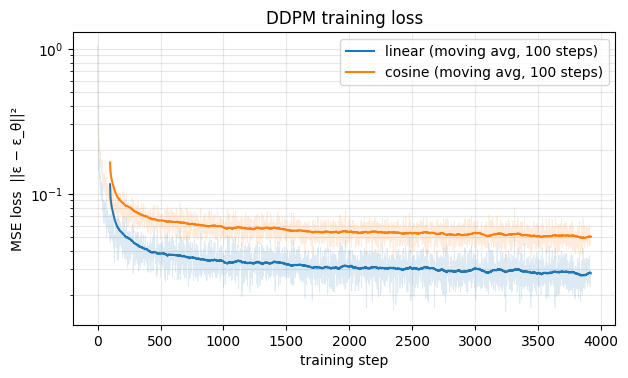

,epochs,batch_size,lr,optimizer,steps,train_time_s,final_loss_last_epoch
linear,28,128,0.0005,AdamW,3920,975.6,0.028
cosine,28,128,0.0005,AdamW,3920,999.5,0.0502


In [15]:
def moving_average(values, k=100):
    """Smooth a noisy loss curve (each point = mean of the previous k steps)."""
    values = np.asarray(values)
    k = min(k, len(values))
    return np.convolve(values, np.ones(k) / k, mode="valid")


plt.figure(figsize=(7, 3.8))
for name, colour in [("linear", "tab:blue"), ("cosine", "tab:orange")]:
    losses = TRAIN_INFO[name]["losses"]
    plt.plot(losses, color=colour, alpha=0.15, lw=0.5)
    plt.plot(np.arange(len(moving_average(losses))) + min(100, len(losses)) - 1,
             moving_average(losses), color=colour, label=f"{name} (moving avg, 100 steps)")
plt.yscale("log")
plt.xlabel("training step")
plt.ylabel("MSE loss  ||ε − ε_θ||²")
plt.title("DDPM training loss")
plt.legend()
plt.grid(alpha=0.3, which="both")
save_fig("A2_loss_curves")

# Check that the two runs really used identical settings (only the schedule differs).
for key in ["epochs", "batch_size", "lr", "optimizer", "steps", "train_images"]:
    assert TRAIN_INFO["linear"][key] == TRAIN_INFO["cosine"][key], key

# Table of training settings for the report.
RESULTS["A2"] = {name: {k: v for k, v in info.items() if k != "losses"} for name, info in TRAIN_INFO.items()}
save_results()
pd.DataFrame(RESULTS["A2"]).T[["epochs", "batch_size", "lr", "optimizer",
                                "steps", "train_time_s", "final_loss_last_epoch"]]

**Note on the loss curves.** The two losses are not directly comparable in value: the loss at each t depends on how noisy
x<sub>t</sub> is, and the two schedules give different noise levels for the same t. With the linear schedule many timesteps are nearly pure
noise, where predicting ε is easy (x<sub>t</sub> ≈ ε), so its average loss is usually lower; that does **not** mean it makes better samples.

## A3. Sampling with DDPM

Reverse step (all 1000 steps, written by me), for t = 999, 998, …, 0:

x<sub>t−1</sub> = (1/√α<sub>t</sub>) · ( x<sub>t</sub> − (β<sub>t</sub>/√(1 − ᾱ<sub>t</sub>)) · ε<sub>θ</sub>(x<sub>t</sub>, t) ) + σ<sub>t</sub> z,  with σ<sub>t</sub>² = β<sub>t</sub> and z ~ N(0, I).

No noise is added at the very last step (t = 0), so the output is the mean prediction.
At every step we can also compute the model's guess of the clean image:
x̂<sub>0</sub> = (x<sub>t</sub> − √(1 − ᾱ<sub>t</sub>) · ε<sub>θ</sub>) / √ᾱ<sub>t</sub>.

**Clipping x̂<sub>0</sub> (as in the original DDPM code, `clip_denoised=True`).** A real image lies in [−1, 1], so before each step I clamp
x̂<sub>0</sub> to [−1, 1] and turn it back into the matching noise, ε = (x<sub>t</sub> − √ᾱ<sub>t</sub> x̂<sub>0</sub>)/√(1 − ᾱ<sub>t</sub>), which then goes into
the same update formula above. Without this, the cosine model breaks at the very first step: its β<sub>999</sub> = 0.999 gives
1/√α<sub>999</sub> ≈ 31.6, so any small error in ε<sub>θ</sub> at t = 999 is multiplied about 32 times: x<sub>998</sub> already has a standard deviation of about 1.5
instead of 1, an input the network never saw in training, and the error keeps growing over the next steps until the samples blow up
and are clamped to black (shown in the extra cell after the trajectories). The linear schedule has β<sub>999</sub> = 0.02 (1/√α ≈ 1.01),
so for it clipping changes almost nothing.

In [16]:
@torch.no_grad()
def ddpm_sample(model, sched, n, seed=SEED, record_at=(), clip_x0=True):
    """Generate n images with the full 1000-step DDPM reverse process.
    record_at: timesteps at which to store (x_t, x0_hat) for the trajectory plot.
    clip_x0: clamp the predicted clean image to [-1, 1] at every step (see the markdown above)."""
    model.eval()
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    x = torch.randn(n, 1, 32, 32, device=DEVICE, generator=gen)     # x_999 ~ N(0, I)
    trajectory = {}
    for t in reversed(range(T)):                                    # 999, 998, ..., 0
        t_batch = torch.full((n,), t, device=DEVICE, dtype=torch.long)
        eps = model(x, t_batch).sample                              # epsilon_theta(x_t, t)
        beta, alpha, abar = sched.betas[t], sched.alphas[t], sched.alpha_bars[t]

        x0_hat = (x - (1 - abar).sqrt() * eps) / abar.sqrt()        # predicted clean image
        if clip_x0:
            x0_hat = x0_hat.clamp(-1, 1)                            # a real image lies in [-1, 1]
            eps = (x - abar.sqrt() * x0_hat) / (1 - abar).sqrt()    # noise that matches the clipped x0_hat
        if t in record_at:
            trajectory[t] = (x.clone(), x0_hat.clamp(-1, 1))

        mean = (x - beta / (1 - abar).sqrt() * eps) / alpha.sqrt()
        if t > 0:
            z = torch.randn(x.shape, device=DEVICE, generator=gen)
            x = mean + beta.sqrt() * z                              # sigma_t = sqrt(beta_t)
        else:
            x = mean                                                # last step: no noise
    return x.clamp(-1, 1), trajectory


def show_grid(images, title, name):
    """Show a batch of 16 images as a 4x4 grid."""
    fig, axes = plt.subplots(4, 4, figsize=(4.5, 4.8))
    for ax, img in zip(axes.flat, images):
        ax.imshow(to_display(img), cmap="gray")
        ax.axis("off")
    plt.suptitle(title, fontsize=10)
    plt.tight_layout()
    save_fig(name)

saved A3_samples_linear.png


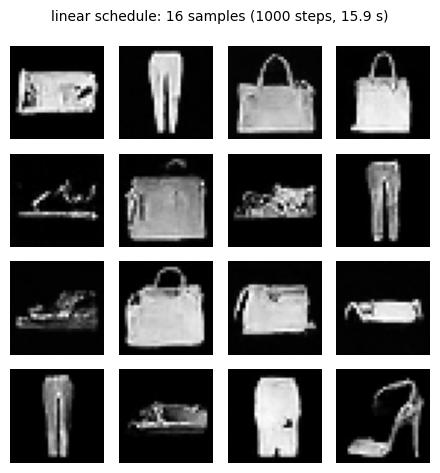

saved A3_samples_cosine.png


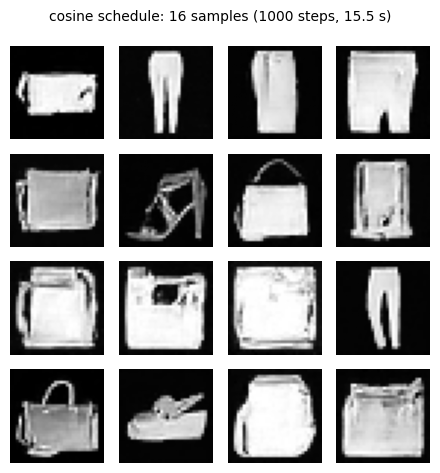

,sampling_time_s_for_16,network_evaluations
linear,15.95,1000.0
cosine,15.54,1000.0


In [17]:
# 4 x 4 grid of samples from each model, and the sampling time.
RESULTS["A3"] = {}
SAMPLES = {}
for name in ["linear", "cosine"]:
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    SAMPLES[name], _ = ddpm_sample(MODELS[name], SCHEDULES[name], n=16)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    sample_time = time.time() - start
    RESULTS["A3"][name] = {"sampling_time_s_for_16": round(sample_time, 2),
                           "network_evaluations": T}
    show_grid(SAMPLES[name], f"{name} schedule: 16 samples ({T} steps, {sample_time:.1f} s)",
              f"A3_samples_{name}")
save_results()
pd.DataFrame(RESULTS["A3"]).T

saved A3_trajectory_linear.png


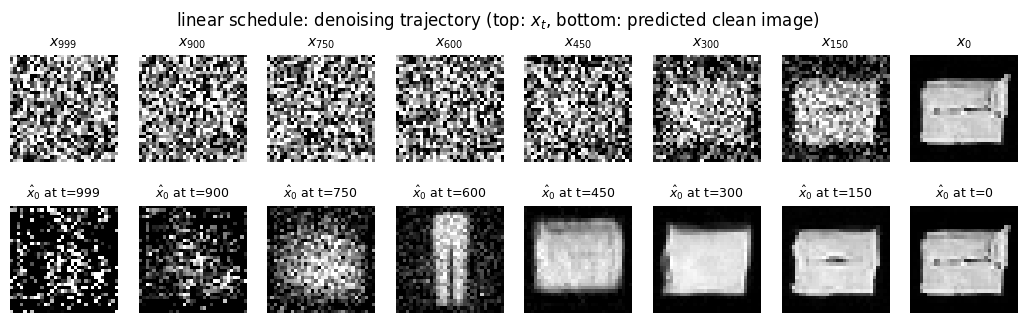

saved A3_trajectory_cosine.png


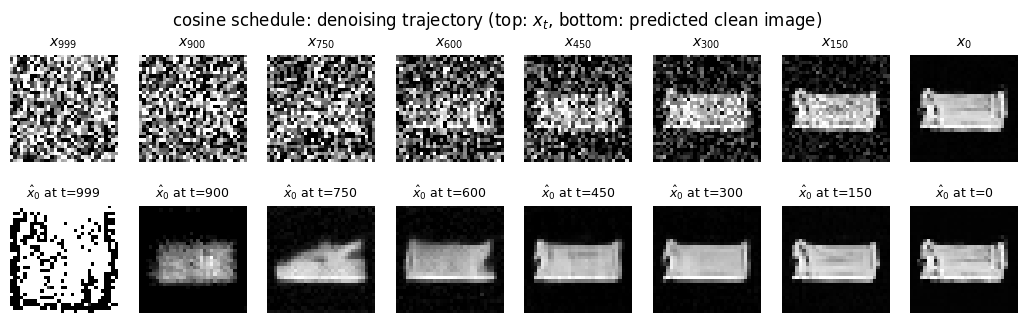

In [18]:
# Denoising trajectory for one sample: x_t (top row) and the predicted clean image x0_hat (bottom row)
# at 8 timesteps from x_999 down to x_0.
TRAJ_T = [999, 900, 750, 600, 450, 300, 150, 0]

for name in ["linear", "cosine"]:
    _, traj = ddpm_sample(MODELS[name], SCHEDULES[name], n=1, seed=SEED + 1, record_at=TRAJ_T)
    fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
    for col, t in enumerate(TRAJ_T):
        xt, x0_hat = traj[t]
        axes[0, col].imshow(to_display(xt), cmap="gray")
        axes[0, col].set_title(f"$x_{{{t}}}$", fontsize=10)
        axes[1, col].imshow(to_display(x0_hat), cmap="gray")
        axes[1, col].set_title(r"$\hat{x}_0$" + f" at t={t}", fontsize=9)
        for row in range(2):
            axes[row, col].axis("off")
    plt.suptitle(f"{name} schedule: denoising trajectory (top: $x_t$, bottom: predicted clean image)")
    save_fig(f"A3_trajectory_{name}")

linear: mean |unclipped - clipped| per pixel = 0.0507  (pixel range is 2)
saved A3_linear_no_clip.png


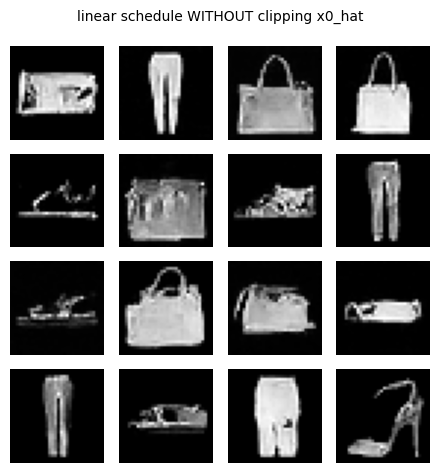

cosine: mean |unclipped - clipped| per pixel = 1.0557  (pixel range is 2)
saved A3_cosine_no_clip.png


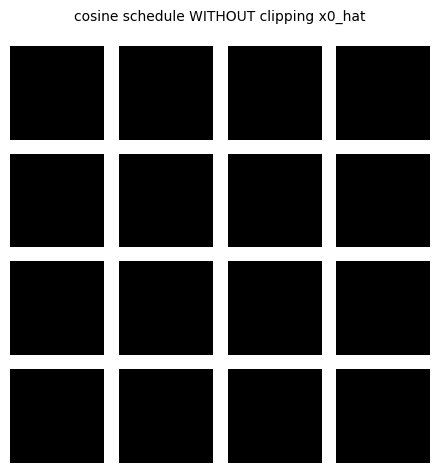

1/sqrt(alpha_999) = 31.6
std of x_999 = 0.99, std of x_998 without clipping = 1.59 (in training x_998 always has std about 1)
pixels stuck at -1 (black) in the final unclipped samples: 62%


In [19]:
# Ablation: the handout formula EXACTLY as written (clip_x0=False), same models and same seed as the grids above.
NO_CLIP = {}
for name in ["linear", "cosine"]:
    NO_CLIP[name], _ = ddpm_sample(MODELS[name], SCHEDULES[name], n=16, clip_x0=False)
    diff = (NO_CLIP[name] - SAMPLES[name]).abs().mean().item()      # same seed -> directly comparable
    RESULTS["A3"][f"{name}_no_clip_mean_abs_diff"] = round(diff, 4)
    print(f"{name}: mean |unclipped - clipped| per pixel = {diff:.4f}  (pixel range is 2)")
    show_grid(NO_CLIP[name], f"{name} schedule WITHOUT clipping x0_hat", f"A3_{name}_no_clip")
x_no_clip = NO_CLIP["cosine"]

# Look at the size of the raw values: re-run one step from x_999 by hand.
cos = SCHEDULES["cosine"]
with torch.no_grad():
    x999 = torch.randn(16, 1, 32, 32, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(SEED))
    eps = MODELS["cosine"](x999, torch.full((16,), T - 1, device=DEVICE)).sample
    mean = (x999 - cos.betas[-1] / (1 - cos.alpha_bars[-1]).sqrt() * eps) / cos.alphas[-1].sqrt()
    x998 = mean + cos.betas[-1].sqrt() * torch.randn_like(mean)
print(f"1/sqrt(alpha_999) = {1 / cos.alphas[-1].sqrt().item():.1f}")
print(f"std of x_999 = {x999.std().item():.2f}, std of x_998 without clipping = {x998.std().item():.2f} "
      "(in training x_998 always has std about 1)")
saturated = (x_no_clip <= -0.99).float().mean().item()
print(f"pixels stuck at -1 (black) in the final unclipped samples: {saturated:.0%}")
RESULTS["A3"]["cosine_no_clip_std_x998"] = round(x998.std().item(), 2)
RESULTS["A3"]["cosine_no_clip_black_fraction"] = round(saturated, 3)
save_results()

**Reading the trajectory plots.** At the first timesteps √ᾱ<sub>t</sub> is almost 0, so x̂<sub>0</sub> = (x<sub>t</sub> − √(1 − ᾱ<sub>t</sub>) ε<sub>θ</sub>)/√ᾱ<sub>t</sub>
divides a small error by a tiny number (1/√ᾱ<sub>999</sub> ≈ 157 for linear and ≈ 20,000 for cosine). That is why the first x̂<sub>0</sub>
panels are saturated noise (they are clamped to [−1, 1] for display). With 0-indexed steps the last panel is x<sub>t</sub> at t = 0, the input of
the final reverse step; the final sample is the output of that step and looks the same (it only removes ≈ 1% noise).

**Comparing the linear and cosine models (A3 answer).**

*Which looks better for my classes (sandal, bag, trouser)?* After the same ~16 minutes of training both models produce
recognisable items, but for my classes the **linear** model's samples look better to me: its grid has a good mix of all three
classes (four or five sandals, about seven bags, three trousers), and the sandals' thin straps and high heels are drawn quite
sharply. The cosine grid is dominated by large, over-bright bag-like shapes (only two sandals and two trousers), and several of
them are flat white blobs with little detail.

*Does this agree with A1?* Only partly. A1 showed that the cosine schedule destroys the image more slowly, and the trajectories
confirm it: the cosine x̂<sub>0</sub> already has the object's outline at t ≈ 900, while the linear x̂<sub>0</sub> is still noise at
t = 900 and a shape only appears around t ≈ 750–600 (in my run it even looks like a trouser at t = 600 before turning into a bag
at t = 450). But a better spread of noise levels during training did not turn into better samples here. Sandals are mostly thin
straps, fine details that are decided in the last, low-noise steps, and a likely reason for the many bags in the cosine grid is
that its model commits to a large, bright shape very early in sampling (around t ≈ 900), when a big rectangle is the safest guess.
The cosine model also only works with x̂<sub>0</sub> clipping, because of its extreme last step β<sub>999</sub> = 0.999, while the
linear samples barely change without it (the ablation cell above). With 16 samples per model and only ~16 minutes of training,
this is a visual judgement, not a measurement; longer training could change the ranking.

*Why does sampling need 1000 network evaluations while one training step needs only one?*
In training we never have to walk the chain: the closed form q(x<sub>t</sub> | x<sub>0</sub>) lets us jump straight to a random
timestep, and the loss at that single t is one (unbiased) term of the full objective, so one forward pass per image is enough.
In sampling we start from pure noise and do not know x<sub>0</sub>, and there is no closed form for the reverse process; each step
x<sub>t−1</sub> depends on x<sub>t</sub>, which itself came from the previous network output. So the 1000 reverse steps form a
sequential chain and need 1000 separate U-Net evaluations that cannot be run in parallel.

---
# Part B: Inside ViT and Swin

**My dataset:** 4 classes of everyday objects (glasses case, perfume, shoe, switch board), 25 photos each (100 photos)
taken with my phone, with different objects, backgrounds, angles and lighting. 92 are real photos; two accidental blurry shots were
removed and the short classes were topped up to 25 with 8 augmented copies (flip + small rotation + crop + brightness/colour change),
marked `_aug` in the file name. They are in Google Drive as `CS5004_A2/photos/<class_name>/<photo>.jpg`; `photos/file_map.csv` maps
every file to the original phone photo.

**Preprocessing:** I do **not** resize by hand. Each photo is opened with `ImageOps.exif_transpose(...)` (so phone photos
are not rotated sideways) and then passed through each model's own timm transform
(`resolve_model_data_config` + `create_transform(is_training=False)`), which resizes the shorter side, centre-crops 224 × 224 and
normalises with the mean and std that the model was trained with. The printout below shows these differ: Swin uses the
ImageNet statistics, while timm's default ViT weights use mean = std = 0.5. That is exactly why each model must get its **own** transform.

In [20]:
import timm

PHOTO_EXTS = {".jpg", ".jpeg", ".png", ".heic", ".webp"}
PHOTO_CLASSES = sorted(p.name for p in PHOTO_DIR.iterdir() if p.is_dir() and not p.name.startswith("."))
PATHS, LABELS = [], []
for label, cls in enumerate(PHOTO_CLASSES):
    files = sorted(p for p in (PHOTO_DIR / cls).iterdir() if p.suffix.lower() in PHOTO_EXTS)
    PATHS += files
    LABELS += [label] * len(files)
LABELS = np.array(LABELS)

print("classes:", PHOTO_CLASSES)
print("photos per class:", {c: int((LABELS == i).sum()) for i, c in enumerate(PHOTO_CLASSES)})
assert len(PHOTO_CLASSES) == 4, "Expected 4 class folders inside photos/"
if not QUICK_TEST:
    assert all((LABELS == i).sum() == 25 for i in range(4)), "Expected 25 photos per class"


def load_photo(path):
    """Open a phone photo the right way up, as RGB."""
    return ImageOps.exif_transpose(Image.open(path)).convert("RGB")

classes: ['glasses_case', 'perfume', 'shoe', 'switch_board']
photos per class: {'glasses_case': 25, 'perfume': 25, 'shoe': 25, 'switch_board': 25}


saved B_dataset_collage.png


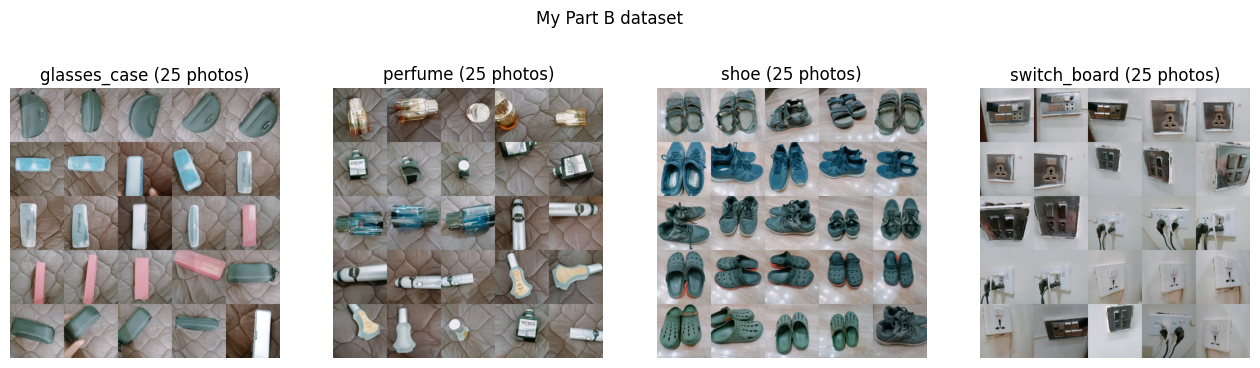

In [21]:
# Collage of my whole dataset (thumbnails are only for this picture; the models use the timm transforms).
THUMB = 96
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (i, cls) in zip(axes, enumerate(PHOTO_CLASSES)):
    files = [p for p, l in zip(PATHS, LABELS) if l == i]
    cols = 5
    rows = math.ceil(len(files) / cols)
    sheet = Image.new("RGB", (cols * THUMB, rows * THUMB), "white")
    for k, p in enumerate(files):
        sheet.paste(ImageOps.fit(load_photo(p), (THUMB, THUMB)), ((k % cols) * THUMB, (k // cols) * THUMB))
    ax.imshow(sheet)
    ax.set_title(f"{cls} ({len(files)} photos)")
    ax.axis("off")
plt.suptitle("My Part B dataset")
save_fig("B_dataset_collage")

In [22]:
# Load the two pretrained models from timm (classification models; we only look at the backbone).
vit = timm.create_model("vit_base_patch16_224", pretrained=True).to(DEVICE).eval()
swin = timm.create_model("swin_tiny_patch4_window7_224", pretrained=True).to(DEVICE).eval()

# Each model's own preprocessing, exactly as the handout asks.
TRANSFORMS = {}
for name, model in [("vit", vit), ("swin", swin)]:
    cfg = timm.data.resolve_model_data_config(model)
    TRANSFORMS[name] = timm.data.create_transform(**cfg, is_training=False)
    print(name, "| weights:", model.pretrained_cfg.get("tag"), "->", TRANSFORMS[name])

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

vit | weights: augreg2_in21k_ft_in1k -> Compose(
    Resize(size=248, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.5000, 0.5000, 0.5000]), std=tensor([0.5000, 0.5000, 0.5000]))
)
swin | weights: ms_in1k -> Compose(
    Resize(size=248, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)


## B1. Trace the shapes

I register a **forward hook** on each module of interest. A hook is a small function that PyTorch calls right after the
module's `forward`, so it can record the output shape without changing the model.
- **ViT:** after `patch_embed`, and after every 3rd transformer block (blocks 3, 6, 9, 12 → `blocks[2]`, `blocks[5]`, `blocks[8]`, `blocks[11]`).
- **Swin:** after `patch_embed` and after each of the 4 stages (`layers[0]` … `layers[3]`).

In [23]:
def trace_shapes(model, module_names, image):
    """Run one image through the model and record the output shape of each named module."""
    shapes, handles = {}, []
    modules = dict(model.named_modules())
    for name in module_names:
        def hook(module, inputs, output, name=name):
            shapes[name] = tuple(output.shape)
        handles.append(modules[name].register_forward_hook(hook))
    with torch.no_grad():
        model(image)
    for h in handles:
        h.remove()                                   # clean up so later runs are not affected
    return shapes


def shape_table(shapes, input_size=224):
    """Turn raw shapes into a table: tokens, channels, spatial grid and downsampling."""
    rows, prev_side = [], input_size
    for name, shp in shapes.items():
        if len(shp) == 4:                            # Swin layout: (B, H, W, C)
            _, h, w, c = shp
            tokens, side, extra = h * w, h, ""
        else:                                        # ViT layout: (B, N, C)
            _, n, c = shp
            side = int(math.isqrt(n))                # 196 -> 14; 197 -> 14 (+1 CLS token)
            tokens, extra = n, " + 1 [CLS]" if n == side * side + 1 else ""
        rows.append({
            "module": name,
            "output shape": str(shp),
            "tokens": tokens,
            "grid": f"{side}×{side}{extra}",
            "channels": c,
            "stride vs input": input_size // side,
            "downsampling here?": f"yes, ÷{prev_side // side}" if side < prev_side else "no",
        })
        prev_side = side
    return pd.DataFrame(rows)


one_image = load_photo(PATHS[0])
# pos_drop runs right after the [CLS] token and the position embedding are added: 196 -> 197 tokens.
VIT_MODULES = ["patch_embed", "pos_drop", "blocks.2", "blocks.5", "blocks.8", "blocks.11"]
SWIN_MODULES = ["patch_embed", "layers.0", "layers.1", "layers.2", "layers.3"]

vit_shapes = trace_shapes(vit, VIT_MODULES, TRANSFORMS["vit"](one_image).unsqueeze(0).to(DEVICE))
swin_shapes = trace_shapes(swin, SWIN_MODULES, TRANSFORMS["swin"](one_image).unsqueeze(0).to(DEVICE))
print("input to both models:", tuple(TRANSFORMS["vit"](one_image).unsqueeze(0).shape))
for name, shp in {**{"vit." + k: v for k, v in vit_shapes.items()},
                  **{"swin." + k: v for k, v in swin_shapes.items()}}.items():
    print(f"{name:18s} {shp}")

input to both models: (1, 3, 224, 224)
vit.patch_embed    (1, 196, 768)
vit.pos_drop       (1, 197, 768)
vit.blocks.2       (1, 197, 768)
vit.blocks.5       (1, 197, 768)
vit.blocks.8       (1, 197, 768)
vit.blocks.11      (1, 197, 768)
swin.patch_embed   (1, 56, 56, 96)
swin.layers.0      (1, 56, 56, 96)
swin.layers.1      (1, 28, 28, 192)
swin.layers.2      (1, 14, 14, 384)
swin.layers.3      (1, 7, 7, 768)


In [24]:
VIT_TABLE = shape_table(vit_shapes)
VIT_TABLE.loc[0, "downsampling here?"] += " (16×16 patch conv, stride 16)"   # name the layer that downsamples
print("ViT-B/16 (vit_base_patch16_224)")
VIT_TABLE

ViT-B/16 (vit_base_patch16_224)


,module,output shape,tokens,grid,channels,stride vs input,downsampling here?
0,patch_embed,"(1, 196, 768)",196,14×14,768,16,"yes, ÷16 (16×16 patch conv, stride 16)"
1,pos_drop,"(1, 197, 768)",197,14×14 + 1 [CLS],768,16,no
2,blocks.2,"(1, 197, 768)",197,14×14 + 1 [CLS],768,16,no
3,blocks.5,"(1, 197, 768)",197,14×14 + 1 [CLS],768,16,no
4,blocks.8,"(1, 197, 768)",197,14×14 + 1 [CLS],768,16,no
5,blocks.11,"(1, 197, 768)",197,14×14 + 1 [CLS],768,16,no


In [25]:
SWIN_TABLE = shape_table(swin_shapes)
SWIN_TABLE.loc[0, "downsampling here?"] += " (4×4 patch conv, stride 4)"
SWIN_TABLE.loc[2:, "downsampling here?"] += " (Patch Merging at stage start)"   # checked in the next cell
print("Swin-T (swin_tiny_patch4_window7_224)")
SWIN_TABLE

Swin-T (swin_tiny_patch4_window7_224)


,module,output shape,tokens,grid,channels,stride vs input,downsampling here?
0,patch_embed,"(1, 56, 56, 96)",3136,56×56,96,4,"yes, ÷4 (4×4 patch conv, stride 4)"
1,layers.0,"(1, 56, 56, 96)",3136,56×56,96,4,no
2,layers.1,"(1, 28, 28, 192)",784,28×28,192,8,"yes, ÷2 (Patch Merging at stage start)"
3,layers.2,"(1, 14, 14, 384)",196,14×14,384,16,"yes, ÷2 (Patch Merging at stage start)"
4,layers.3,"(1, 7, 7, 768)",49,7×7,768,32,"yes, ÷2 (Patch Merging at stage start)"


In [26]:
# Where exactly does Swin downsample? In timm the Patch Merging layer sits at the START of stages 2, 3 and 4.
for i, layer in enumerate(swin.layers):
    print(f"layers[{i}].downsample = {type(layer.downsample).__name__:14s}  depth = {len(layer.blocks)} blocks")

# The hint from the handout: features_only=True drops the classifier head and returns the 4 stage outputs,
# exactly what a detection/segmentation backbone (e.g. FPN) receives.
swin_backbone = timm.create_model("swin_tiny_patch4_window7_224", pretrained=True, features_only=True).to(DEVICE).eval()
with torch.no_grad():
    feats = swin_backbone(TRANSFORMS["swin"](one_image).unsqueeze(0).to(DEVICE))
print("\nfeatures_only outputs (NHWC; an FPN would permute them to NCHW):")
for f, info in zip(feats, swin_backbone.feature_info.get_dicts()):
    print(f"  {info['module']:10s} shape {tuple(f.shape)}  stride {info['reduction']}  channels {info['num_chs']}")

layers[0].downsample = Identity        depth = 2 blocks
layers[1].downsample = PatchMerging    depth = 2 blocks
layers[2].downsample = PatchMerging    depth = 6 blocks
layers[3].downsample = PatchMerging    depth = 2 blocks

features_only outputs (NHWC; an FPN would permute them to NCHW):
  layers.0   shape (1, 56, 56, 96)  stride 4  channels 96
  layers.1   shape (1, 28, 28, 192)  stride 8  channels 192
  layers.2   shape (1, 14, 14, 384)  stride 16  channels 384
  layers.3   shape (1, 7, 7, 768)  stride 32  channels 768


In [27]:
# Parameter counts.
def count_params(model):
    return sum(p.numel() for p in model.parameters())


RESULTS["B1"] = {
    "vit_params": count_params(vit),
    "swin_params": count_params(swin),
    "swin_backbone_params_features_only": count_params(swin_backbone),
    "vit_table": VIT_TABLE.to_dict(orient="records"),
    "swin_table": SWIN_TABLE.to_dict(orient="records"),
}
save_results()
print(f"ViT-B/16 parameters: {RESULTS['B1']['vit_params']:,} ({RESULTS['B1']['vit_params'] / 1e6:.1f} M)")
print(f"Swin-T   parameters: {RESULTS['B1']['swin_params']:,} ({RESULTS['B1']['swin_params'] / 1e6:.1f} M)")
print(f"Swin-T backbone only (features_only): {RESULTS['B1']['swin_backbone_params_features_only']:,}")

ViT-B/16 parameters: 86,567,656 (86.6 M)
Swin-T   parameters: 28,288,354 (28.3 M)
Swin-T backbone only (features_only): 27,517,818


**What the tables show.**
- **ViT** cuts the 224 × 224 image into 16 × 16 patches once (224/16 = 14 → 14 × 14 = 196 tokens of width 768), then adds the
  [CLS] token (197 tokens). After that, **no block changes the shape**: every block outputs 197 × 768, so ViT has one scale (stride 16).
- **Swin** cuts the image into 4 × 4 patches (56 × 56 = 3136 tokens, C = 96). Stage 1 keeps this size; **Patch Merging at the start of
  stages 2, 3 and 4** joins each 2 × 2 group of neighbouring tokens, so the grid halves (56 → 28 → 14 → 7) and the channels double
  (96 → 192 → 384 → 768). This gives feature maps at strides 4, 8, 16 and 32.

**Why Swin's feature maps can feed an FPN directly but ViT's cannot (B1 answer).**
An FPN needs a pyramid of feature maps at several resolutions (like ResNet's C2–C5 at strides 4, 8, 16, 32), and Swin's four
stages give exactly that: 56×56×96, 28×28×192, 14×14×384 and 7×7×768. ViT keeps a single 14 × 14 × 768 map (stride 16) in every
block, so there is no high-resolution map for small objects and no low-resolution one for large objects; we would have to build the
pyramid ourselves (e.g. by up/down-sampling), and ViT's global attention also grows quadratically with the number of tokens,
which is costly for the large images used in detection, while Swin's window attention grows only linearly.

## B2. Linear probe on my photos

Both backbones are **frozen** (`eval()` + `torch.no_grad()`, no training). Each photo becomes one feature vector:
- **ViT:** the [CLS] token from the final (normalised) token sequence → 768 numbers.
- **Swin:** global average pooling of the final 7 × 7 × 768 feature map → 768 numbers.

Then a logistic-regression classifier is trained on each set of features with the **same stratified 70/30 split**.
The test photos are always real photos; the few augmented copies (used to top up short classes to 25) only go into training.

In [28]:
@torch.no_grad()
def extract_features(model, transform, kind, batch_size=16):
    """One frozen feature vector per photo: [CLS] token for ViT, global average pooling for Swin."""
    feats = []
    for i in range(0, len(PATHS), batch_size):
        batch = torch.stack([transform(load_photo(p)) for p in PATHS[i:i + batch_size]]).to(DEVICE)
        out = model.forward_features(batch)          # backbone only, no classification head
        if kind == "vit":
            vec = out[:, 0]                          # (B, 197, 768) -> [CLS] token (B, 768)
        else:
            vec = out.mean(dim=(1, 2))               # (B, 7, 7, 768) -> average over H, W -> (B, 768)
        feats.append(vec.cpu())
    return torch.cat(feats).numpy()


FEATURES = {
    "vit": extract_features(vit, TRANSFORMS["vit"], "vit"),
    "swin": extract_features(swin, TRANSFORMS["swin"], "swin"),
}
for k, v in FEATURES.items():
    print(k, "features:", v.shape)

vit features: (100, 768)
swin features: (100, 768)


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix, ConfusionMatrixDisplay

# ONE stratified 70/30 split of the photo indices, used for BOTH backbones.
# Augmented photos (file names ending in "_aug") are flipped/rotated copies of real photos. If one landed in the
# test set while its original was in the training set, the probe would be tested on a photo it has already seen.
# So the 30 test photos are drawn (stratified) from the REAL photos only, and every augmented photo goes to training.
is_aug = np.array([p.stem.endswith("_aug") for p in PATHS])
real_idx, aug_idx = np.where(~is_aug)[0], np.where(is_aug)[0]
n_test = round(0.3 * len(PATHS))                                   # 30 of 100
train_real, TEST_IDX = train_test_split(real_idx, test_size=n_test, stratify=LABELS[real_idx], random_state=SEED)
TRAIN_IDX = np.concatenate([train_real, aug_idx])
assert not is_aug[TEST_IDX].any()
print("real photos:", len(real_idx), "| augmented:", len(aug_idx))
print("train:", len(TRAIN_IDX), "test:", len(TEST_IDX),
      "| test per class:", np.bincount(LABELS[TEST_IDX]), "| train per class:", np.bincount(LABELS[TRAIN_IDX]))


def linear_probe(features):
    """Standardise the features, then fit a logistic-regression classifier on the training split.
    Returns the predicted labels and the predicted class probabilities for the test photos."""
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    clf.fit(features[TRAIN_IDX], LABELS[TRAIN_IDX])
    return clf.predict(features[TEST_IDX]), clf.predict_proba(features[TEST_IDX])


PREDS, PROBS = {}, {}
for name, f in FEATURES.items():
    PREDS[name], PROBS[name] = linear_probe(f)

RESULTS["B2"] = {"classes": PHOTO_CLASSES, "n_train": len(TRAIN_IDX), "n_test": len(TEST_IDX)}
y_test = LABELS[TEST_IDX]
for name, pred in PREDS.items():
    RESULTS["B2"][name] = {
        "accuracy": round(accuracy_score(y_test, pred), 4),
        "macro_f1": round(f1_score(y_test, pred, average="macro"), 4),
        "n_wrong": int((pred != y_test).sum()),
        # how confident the probe is in the right answer (useful if both get the same accuracy)
        "test_log_loss": round(log_loss(y_test, PROBS[name], labels=range(len(PHOTO_CLASSES))), 4),
        "mean_prob_true_class": round(float(PROBS[name][np.arange(len(y_test)), y_test].mean()), 4),
        "confusion_matrix": confusion_matrix(y_test, pred).tolist(),
    }
save_results()
pd.DataFrame({k: {m: RESULTS["B2"][k][m] for m in ["accuracy", "macro_f1", "n_wrong", "test_log_loss",
                                                     "mean_prob_true_class"]}
              for k in ["vit", "swin"]}).T

real photos: 92 | augmented: 8
train: 70 test: 30 | test per class: [8 7 8 7] | train per class: [17 18 17 18]


,accuracy,macro_f1,n_wrong,test_log_loss,mean_prob_true_class
vit,1.0,1.0,0.0,0.0113,0.9898
swin,1.0,1.0,0.0,0.0168,0.9845


saved B2_confusion_matrices.png


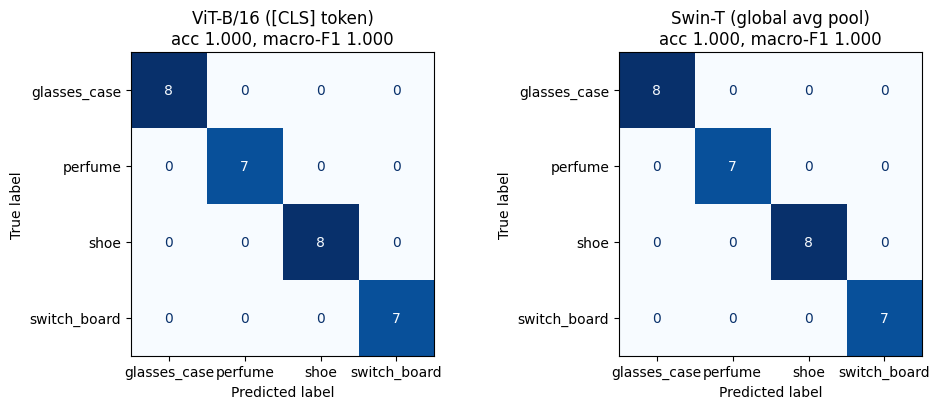

In [30]:
# Both confusion matrices side by side.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, name, title in zip(axes, ["vit", "swin"], ["ViT-B/16 ([CLS] token)", "Swin-T (global avg pool)"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, PREDS[name]), display_labels=PHOTO_CLASSES).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{title}\nacc {RESULTS['B2'][name]['accuracy']:.3f}, macro-F1 {RESULTS['B2'][name]['macro_f1']:.3f}")
plt.tight_layout()
save_fig("B2_confusion_matrices")

vit: 0 shown of 0 misclassified
swin: 0 shown of 0 misclassified
saved B2_misclassified.png


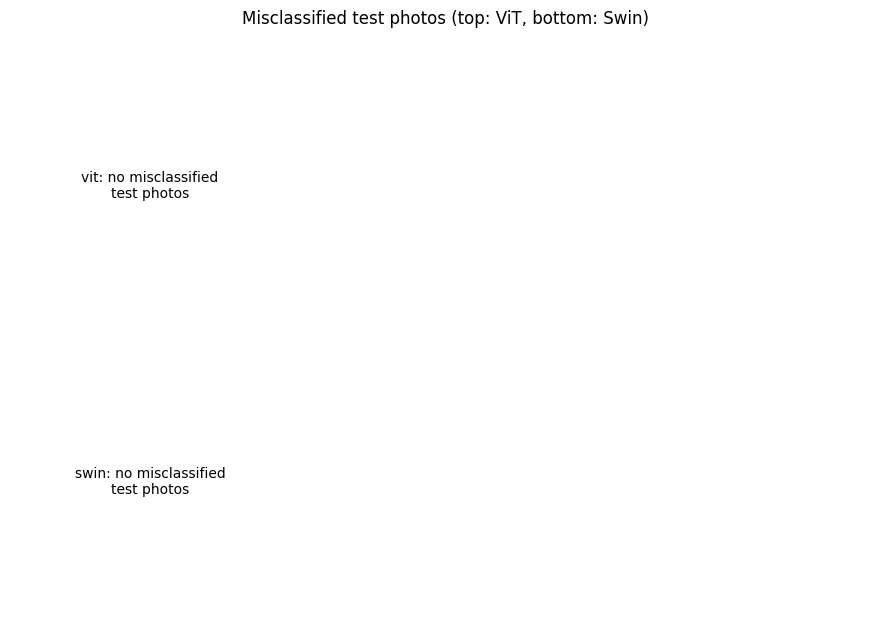

In [31]:
# Up to 3 misclassified test photos per model (or all of them if there are fewer).
fig, axes = plt.subplots(2, 3, figsize=(9, 6.4))
for row, name in enumerate(["vit", "swin"]):
    wrong = [i for i, p, y in zip(TEST_IDX, PREDS[name], y_test) if p != y][:3]
    pred_of = dict(zip(TEST_IDX, PREDS[name]))
    for col in range(3):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(wrong):
            i = wrong[col]
            ax.imshow(ImageOps.fit(load_photo(PATHS[i]), (224, 224)))   # square thumbnail for display only
            ax.set_title(f"{name}: true {PHOTO_CLASSES[LABELS[i]]}\npred {PHOTO_CLASSES[pred_of[i]]}", fontsize=9)
        elif col == 0:
            ax.text(0.5, 0.5, f"{name}: no misclassified\ntest photos", ha="center", va="center")
    print(f"{name}: {len(wrong)} shown of {RESULTS['B2'][name]['n_wrong']} misclassified")
plt.suptitle("Misclassified test photos (top: ViT, bottom: Swin)")
plt.tight_layout()
save_fig("B2_misclassified")

**Which backbone gave better features for my data, and why (B2 answer).**

Background that explains the result (the next cell prints the actual comparison from my numbers):
- **ViT-B/16** is about 3× larger (≈86 M vs ≈28 M parameters) and timm's default weights (`augreg2_in21k_ft_in1k`, printed when the
  models were loaded) were pre-trained on ImageNet-21k (14 M images, 21k classes) before ImageNet-1k fine-tuning, so its [CLS] token
  carries very general, semantic features. Swin-T's weights (`ms_in1k`) saw only ImageNet-1k.
- **Swin-T** builds features hierarchically with local window attention and patch merging, so the last map mixes fine local detail
  (texture, edges) with the overall shape, and global average pooling summarises all 49 positions, which is robust when the object is
  off-centre or the background changes.
- With only 30 test photos, **one error = 3.3% accuracy**, so a difference of one or two photos is within noise.

In [32]:
# B2 discussion written from the measured numbers (make_report.py uses the same rule, so notebook and report agree).
b2 = RESULTS["B2"]
nice = {"vit": "ViT-B/16", "swin": "Swin-T"}
for k in ["vit", "swin"]:
    print(f"{nice[k]:9s} accuracy {b2[k]['accuracy']:.3f}  macro-F1 {b2[k]['macro_f1']:.3f}  "
          f"wrong {b2[k]['n_wrong']}/{b2['n_test']}  log-loss {b2[k]['test_log_loss']:.3f}  "
          f"mean p(true class) {b2[k]['mean_prob_true_class']:.3f}")

gap = b2["vit"]["n_wrong"] - b2["swin"]["n_wrong"]          # > 0 means Swin made fewer mistakes
if gap == 0:
    # Same number of errors: break the tie with confidence (lower test log-loss = more confident and correct).
    sure = min(["vit", "swin"], key=lambda k: b2[k]["test_log_loss"])
    other = "swin" if sure == "vit" else "vit"
    verdict = (f"Both backbones made the same number of test errors ({b2['vit']['n_wrong']}/{b2['n_test']}), but "
               f"{nice[sure]} was more confident in the right answers (test log-loss {b2[sure]['test_log_loss']:.3f} vs "
               f"{b2[other]['test_log_loss']:.3f}, mean probability of the true class {b2[sure]['mean_prob_true_class']:.3f} "
               f"vs {b2[other]['mean_prob_true_class']:.3f}).")
    if b2[other]["test_log_loss"] - b2[sure]["test_log_loss"] < 0.01:
        verdict += " That gap is tiny, so on my photos the two backbones are effectively equally good."
    else:
        verdict += f" So {nice[sure]}'s features separate my classes slightly better."
else:
    winner, loser = ("swin", "vit") if gap > 0 else ("vit", "swin")
    verdict = (f"{nice[winner]} gave the better features on my photos: {b2[winner]['n_wrong']} vs "
               f"{b2[loser]['n_wrong']} wrong out of {b2['n_test']} "
               f"(macro-F1 {b2[winner]['macro_f1']:.3f} vs {b2[loser]['macro_f1']:.3f}).")
    if abs(gap) <= 2:
        verdict += " The gap is only one or two photos, so it is small and could change with a different split."
print()
print(verdict)

ViT-B/16  accuracy 1.000  macro-F1 1.000  wrong 0/30  log-loss 0.011  mean p(true class) 0.990
Swin-T    accuracy 1.000  macro-F1 1.000  wrong 0/30  log-loss 0.017  mean p(true class) 0.985

Both backbones made the same number of test errors (0/30), but ViT-B/16 was more confident in the right answers (test log-loss 0.011 vs 0.017, mean probability of the true class 0.990 vs 0.985). That gap is tiny, so on my photos the two backbones are effectively equally good.


---
# Part C: Working by Hand (Swin, d = 5)

**Settings for d = 5:** image H × W × 3 = **448 × 448 × 3**, **C = 128**, patch size 4, window size M = 7, depths 2, 2, 6, 2.

**1. Output sizes**
- Patch partition + linear embedding: each 4 × 4 × 3 = 48-value patch becomes one token of size C → 448/4 = **112**, so **112 × 112 × 128**.
- Stage 1 (linear embedding + 2 Swin blocks, no merging): **112 × 112 × 128**.
- Stage 2 (patch merging: ÷2 in h and w, ×2 channels, then 2 blocks): 112/2 = 56 → **56 × 56 × 256**.
- Stage 3 (patch merging, then 6 blocks): 56/2 = 28 → **28 × 28 × 512**.
- Stage 4 (patch merging, then 2 blocks): 28/2 = 14 → **14 × 14 × 1024**.

**2. Number of windows** (non-overlapping 7 × 7 windows: (h/M) × (w/M))
- Stage 1: (112/7)² = 16² = **256** windows
- Stage 2: (56/7)² = 8² = **64** windows
- Stage 3: (28/7)² = 4² = **16** windows
- Stage 4: (14/7)² = 2² = **4** windows

(All sizes divide by 7 exactly, so no padding is needed. Each window has M² = 49 tokens.)

**3. Attention cost for one attention layer in stage 1** (h = w = 112, hw = 12,544, C = 128, C² = 16,384, M = 7)

Ω(MSA) = 4hwC² + 2(hw)²C
- 4hwC² = 4 × 12,544 × 128² = 4 × 12,544 × 16,384 = **822,083,584**
- 2(hw)²C = 2 × 12,544² × 128 = 2 × 157,351,936 × 128 = **40,282,095,616**
- Ω(MSA) = 822,083,584 + 40,282,095,616 = **41,104,179,200 ≈ 4.11 × 10¹⁰**

Ω(W-MSA) = 4hwC² + 2M²hwC
- 4hwC² = **822,083,584** (same projection cost as above)
- 2M²hwC = 2 × 49 × 12,544 × 128 = **157,351,936**
- Ω(W-MSA) = 822,083,584 + 157,351,936 = **979,435,520 ≈ 9.79 × 10⁸**

**Ratio:** Ω(MSA) / Ω(W-MSA) = 41,104,179,200 / 979,435,520 ≈ **41.97**

A quick way to check it: dividing top and bottom by 2hwC gives (2C + hw) / (2C + M²) = (256 + 12,544) / (256 + 49) = 12,800 / 305 ≈ **41.97**.
So global attention in stage 1 would cost about **42 times** more than window attention. The (hw)² term (quadratic in the number
of tokens) is 98% of the MSA cost, which is what makes global MSA impractical at high resolution, while W-MSA is linear in hw.
Comparing only the attention terms: 2(hw)²C / 2M²hwC = hw/M² = 12,544/49 = **256**, which is exactly the number of stage-1 windows.
(The 4hwC² projection term is the same in both, which is why the full ratio, 42, is much smaller than 256.)

In [33]:
# Check the hand calculations above with code (same formulas, same numbers).
PART_C_SETTINGS = {0: (224, 64), 1: (224, 96), 2: (224, 128), 3: (448, 64), 4: (448, 96),
                   5: (448, 128), 6: (672, 64), 7: (672, 96), 8: (672, 128), 9: (896, 96)}
H, C = PART_C_SETTINGS[d]
P, M, DEPTHS = 4, 7, (2, 2, 6, 2)

rows = []
side, ch = H // P, C
rows.append({"layer": "linear embedding", "output (h×w×c)": f"{side}×{side}×{ch}", "windows": "-"})
for stage in range(4):
    if stage > 0:
        side, ch = side // 2, ch * 2                  # patch merging: halve h and w, double channels
    rows.append({"layer": f"stage {stage + 1} ({DEPTHS[stage]} blocks)",
                 "output (h×w×c)": f"{side}×{side}×{ch}",
                 "windows": f"({side}/{M})² = {(side // M) ** 2}"})
display(pd.DataFrame(rows))

hw = (H // P) ** 2
proj = 4 * hw * C ** 2
msa = proj + 2 * hw ** 2 * C
wmsa = proj + 2 * M ** 2 * hw * C
print(f"hw = {hw:,}")
print(f"Omega(MSA)   = {proj:,} + {2 * hw ** 2 * C:,} = {msa:,}")
print(f"Omega(W-MSA) = {proj:,} + {2 * M ** 2 * hw * C:,} = {wmsa:,}")
print(f"ratio        = {msa / wmsa:.2f}")

RESULTS["C"] = {"H": H, "C": C, "hw": hw, "omega_msa": msa, "omega_wmsa": wmsa, "ratio": round(msa / wmsa, 2),
                "table": rows}
save_results()

,layer,output (h×w×c),windows
0,linear embedding,112×112×128,-
1,stage 1 (2 blocks),112×112×128,(112/7)² = 256
2,stage 2 (2 blocks),56×56×256,(56/7)² = 64
3,stage 3 (6 blocks),28×28×512,(28/7)² = 16
4,stage 4 (2 blocks),14×14×1024,(14/7)² = 4


hw = 12,544
Omega(MSA)   = 822,083,584 + 40,282,095,616 = 41,104,179,200
Omega(W-MSA) = 822,083,584 + 157,351,936 = 979,435,520
ratio        = 41.97


---
## Files produced
Everything below is in `outputs/` (in Google Drive: `MyDrive/CS5004_A2/outputs/`). The checkpoints and the `photos/` folder are what
go into the shared Drive folder linked in the report.

In [34]:
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(OUT)}  ({p.stat().st_size / 1e6:.2f} MB)")

ckpt/ddpm_cosine.pt  (15.89 MB)
ckpt/ddpm_linear.pt  (15.89 MB)
figures/A1_alpha_bar.png  (0.05 MB)
figures/A1_forward_grid.png  (0.08 MB)
figures/A2_loss_curves.png  (0.09 MB)
figures/A3_cosine_no_clip.png  (0.01 MB)
figures/A3_linear_no_clip.png  (0.04 MB)
figures/A3_samples_cosine.png  (0.05 MB)
figures/A3_samples_linear.png  (0.04 MB)
figures/A3_trajectory_cosine.png  (0.06 MB)
figures/A3_trajectory_linear.png  (0.07 MB)
figures/B2_confusion_matrices.png  (0.05 MB)
figures/B2_misclassified.png  (0.03 MB)
figures/B_dataset_collage.png  (1.15 MB)
results.json  (0.01 MB)
